<div dir="rtl">

# المشروع الختامي: تصميم تجربة وتحليلها

**برنامج التجارب واختبارات A/B والاستدلال السببي**، العرض يوم الأربعاء 11 نوفمبر 2026

تعمل على المشروع **فرديًا أو ضمن فريق صغير** حسب ما يحدده المدرب.

| القسم | موعد كتابته |
|---|---|
| 0. بيانات المشروع، 1. السؤال والفرضية، 2. التصميم | الأحد، الجلسة الرابعة |
| 3. حجم العينة والمدة | الإثنين، الجلسة الرابعة |
| 4. خطة التحليل، 5. إنشاء البيانات، 6. فحوص الثقة، 7. التحليل | الثلاثاء، الجلسة الرابعة |
| 8. (اختياري) بديل شبه تجريبي | الثلاثاء، الجلسة الرابعة |
| 9. التقرير والتوصية | الأربعاء، الجلسة الثانية |
| 10. التسليم على GitHub | آخر اليوم الرابع، الأربعاء |

**المطلوب تسليمه آخر اليوم الرابع:** مستودع عام على GitHub فيه هذا الدفتر مكتملًا وملف README، وتقرير من صفحة واحدة (القسم 9)، وعرض مدته 10 دقائق. خطوات الحفظ في GitHub وقالب README في القسم 10.

> البيانات هنا من **محاكاة**: أنت تحدد الأثر الحقيقي بنفسك، ثم ترى هل يصل تحليلك إليه. في الواقع لا نعرف الأثر الحقيقي، ولهذا نتدرب على المحاكاة أولًا.

</div>

<div dir="rtl">

## 0. بيانات المشروع

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| اسم المشروع |  |
| الاسم، أو أسماء أعضاء الفريق |  |
| الجهة أو المنتج |  |

</div>

<div dir="rtl">

## 1. السؤال والفرضية

</div>

هل يؤدي إرسال إشعار فوري (Push Notification) يتضمن رسالة تحفيزية شخصية مع عداد تنازلي للخصم إلى زيادة معدل إتمام عمليات الشراء مقارنة بالإشعار العادي؟"
Bullet القرار: تفعيل إشعار فوري يحتوي على عداد تنازلي للخصم للمستخدمين الجدد لتحفيزهم على الشراء.
Bullet الفرضية (إذا... فسوف... لأن...): إذا أرسلنا إشعاراً فورياً يتضمن عداداً تنازلياً للخصم للمجموعة التجريبية، فسوف يرتفع معدل إتمام عمليات الشراء، لأن شعور العميل باستعجال الوقت وقرب انتهاء الخصم يدفعه لاتخاذ قرار الشراء بشكل أسرع.
Bullet ما الذي يجعلنا نغير رأينا؟ إذا أظهرت نتائج التجربة انخفاضاً أو عدم وجود فرق جوهري في المبيعات بين المجموعتين، أو إذا كان معدل إلغاء الطلبات مرتفعاً نتيجة إزعاج الإشعارات المتكررة.


<div dir="rtl">

## 2. التصميم

</div>

| البند | القيمة |
| :--- | :--- |
| **وحدة العشوائية (Analysis Unit)** | المستخدم (User) |
| **نسبة التوزيع (Assignment Share)** | 50% للمجموعة التجريبية و 50% للمجموعة الضابطة |
| **المقياس الرئيسي (Primary Metric)** | معدل إتمام عمليات الشراء (Conversion Rate) |
| **مقاييس ثانوية (Secondary Metrics)** | متوسط إجمالي الإيرادات لكل مستخدم، معدل النقر على الإشعار |
| **مقاييس الحماية (Guardrail Metrics)** | معدل إلغاء الطلبات، معدل إلغاء الاشتراك من الإشعارات |
| **شرط SUTVA** | يفترض عدم وجود تداخل أو تأثير بين خيارات المستخدمين في المجموعتين |


<div dir="rtl">

## أدوات جاهزة

شغّل الخلية التالية بدون تعديل. فيها كل الدوال التي استخدمناها في الأيام الأربعة.

</div>

In [18]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], f_exp=[total * (1 - expected_share_b), total * expected_share_b])
    verdict = "خلل في التوزيع (SRM)، لا تثق بالنتائج" if p < threshold else "التوزيع سليم"
    say(f"A={n_a:,}   B={n_b:,}   χ²={chi2:.2f}   p={p:.2g}   النتيجة: {verdict}")
    return p


def diff_ci(a, b, alpha=0.05):
    """الفرق بين B وA مع فترة الثقة وقيمة p (بالتقريب الطبيعي)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return {"الفرق": diff, "أدنى 95%": diff - z * se, "أعلى 95%": diff + z * se, "SE": se,
            "p": 2 * stats.norm.sf(abs(diff / se))}


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


say("الأدوات جاهزة")

<div dir="rtl">

## 3. حجم العينة والمدة

عدّل قيم `CONFIG` حسب مشروعك. القيم تحت عنوان **"التصميم"** تعرفها أو تقدرها من الواقع. أما القيم تحت عنوان **"المحاكاة"** فهي "الحقيقة" التي لا يعرفها المحلل في الواقع، وتحددها هنا للتدريب فقط.

</div>

In [19]:
CONFIG = {
    "project": "إشعار الخصم المؤقت والعداد التنازلي",
    "baseline_conversion": 0.05,
    "mde_abs": 0.02,
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 1000,
    "treatment_share": 0.5,
    "true_lift_abs": 0.02,
    "order_value_mean": 120,
    "order_value_sd": 50,
    "order_value_effect": 0,
    "margin": 0.25,
    "extra_cost_per_order_b": 0,
    "cancel_rate": 0.05,
    "cancel_effect": 0.00,
    "support_rate": 0.03,
    "support_effect": 0.000,
    "activity_strength": 0.8,
    "novelty_boost": 0.0,
    "srm_bug_share": 0.0,
    "seed": 2026,
}

c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة لكل مجموعة: {n_per_group:,} مستخدم")
say(f"المدة المقدرة للأيام: {days} يوم")


In [20]:
c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")
n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")
for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")

<div dir="rtl">

اكتب قرارك هنا.
المدة المقدرة تعتبر مقبولة ومنطقية جداً بالنسبة لقدرة المتجر وحجم الزيارات اليومية، ولن تحتاج التجربة إلى تمديد إضافي.

</div>

<div dir="rtl">

## 4. خطة التحليل

اكتبها **قبل** تشغيل القسم 5. وأي تغيير تجريه بعد رؤية النتائج يجب أن تذكره في التقرير.

</div>


1. **فحص نسبة التوزيع (SRM):** استخدام اختبار Chi-square للتأكد من عدم وجود تفاوت كبير أو خلل في توزيع المستخدمين بين المجموعة التجريبية والضابطة (بنسبة 50/50).
2. **المقياس الرئيسي:** معدل إتمام عمليات الشراء (Conversion Rate).
3. **مقاييس ثانوية:** إجمالي الإيرادات لكل مستخدم، معدل النقر على الإشعار.
4. **مقاييس الحماية:** معدل إلغاء الطلبات وإلغاء الاشتراك من الإشعارات.
5. **متى نحلل:** بعد انتهاء المدة الزمنية المحددة للتجربة (أو اكتمال حجم العينة المستهدف).
6. **قاعدة القرار:** اعتماد ميزة إشعار الخصم المؤقت إذا أظهر التحليل دلالة إحصائية واضحة (p-value < 0.05) في زيادة معدل الشراء دون الإضرار بمقاييس الحماية.



<div dir="rtl">

## 5. إنشاء البيانات بالمحاكاة

تنشئ المحاكاة كل المستخدمين الذين يدخلون التجربة خلال المدة، وكل مستخدم في صف واحد. لكل مستخدم: النسخة، ويوم الدخول، وطلباته في آخر 90 يومًا قبل التجربة، وهل طلب، وقيمة الطلب، والربح، والإلغاء، والتواصل مع الدعم.

</div>

In [21]:
def simulate_experiment(cfg, duration_days):
    """كل المستخدمين الذين يدخلون خلال مدة التجربة (المدة مضروبة في عدد المستخدمين اليومي)."""
    r = np.random.default_rng(cfg["seed"])
    n = duration_days * cfg["daily_new_users"]
    is_b = (r.random(n) < cfg["treatment_share"]).astype(int)
    day = r.integers(1, duration_days + 1, n)
    activity = r.normal(0, 1, n)                                             # نشاط المستخدم (لا نقيسه مباشرة)
    base = cfg["baseline_conversion"]
    logit = np.log(base / (1 - base)) + cfg["activity_strength"] * activity
    p0 = 1 / (1 + np.exp(-logit))
    p0 = np.clip(p0 * base / p0.mean(), 0, 1)                                # نضبط المتوسط ليساوي خط الأساس
    pre_orders_90d = r.poisson(5 * p0 / base)                                # الطلبات في آخر 90 يومًا
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(day - 1) / 3))
    ordered = r.binomial(1, np.clip(p0 + lift * is_b, 0, 1))
    value = np.maximum(10, r.normal(cfg["order_value_mean"] + cfg["order_value_effect"] * is_b, cfg["order_value_sd"]))
    order_value = np.where(ordered == 1, value, np.nan)
    revenue = ordered * value
    profit = ordered * (cfg["margin"] * value - cfg["extra_cost_per_order_b"] * is_b)
    cancelled = np.where(ordered == 1, r.binomial(1, np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * is_b, 0, 1)), np.nan)
    support = r.binomial(1, np.clip(cfg["support_rate"] + cfg["support_effect"] * is_b, 0, 1))
    df = pd.DataFrame({"variant": np.where(is_b == 1, "B", "A"), "day": day, "pre_orders_90d": pre_orders_90d,
                       "ordered": ordered, "order_value": order_value, "revenue": revenue, "profit": profit,
                       "cancelled": cancelled, "contacted_support": support})
    if cfg["srm_bug_share"] > 0:                                              # خلل: سجلات ضائعة من B لقليلي النشاط
        lost = (df["variant"] == "B") & (activity < 0) & (r.random(n) < cfg["srm_bug_share"] * 2)
        df = df[~lost]
    return df.reset_index(drop=True)


data = simulate_experiment(CONFIG, days)
say(f"عدد المستخدمين: {len(data):,}")
data.head()

,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,B,1,3,0,NaN,0.0,0.0,NaN,0
1,A,7,6,0,NaN,0.0,0.0,NaN,0
2,B,2,4,0,NaN,0.0,0.0,NaN,0
3,B,5,5,0,NaN,0.0,0.0,NaN,0
4,B,4,13,0,NaN,0.0,0.0,NaN,0


<div dir="rtl">

## 6. فحوص الثقة

</div>

In [22]:
counts = data["variant"].value_counts()
srm_check(counts.get("A", 0), counts.get("B", 0), CONFIG["treatment_share"]);

<div dir="rtl">

## 7. التحليل

### 7.1 المقياس الرئيسي، مع CUPED

</div>

In [23]:
A, B = data[data.variant == "A"], data[data.variant == "B"]
primary = diff_ci(A["ordered"], B["ordered"])

theta = np.cov(data["ordered"], data["pre_orders_90d"])[0, 1] / data["pre_orders_90d"].var(ddof=1)
adjusted = data["ordered"] - theta * (data["pre_orders_90d"] - data["pre_orders_90d"].mean())
primary_cuped = diff_ci(adjusted[data.variant == "A"], adjusted[data.variant == "B"])

out = pd.DataFrame([primary, primary_cuped], index=["بدون تعديل", "مع CUPED"])
out[["الفرق", "أدنى 95%", "أعلى 95%"]] *= 100
say(f"نسبة الطلب في A: {A['ordered'].mean():.2%}، وفي B: {B['ordered'].mean():.2%}")
say(f"انخفاض التباين بطريقة CUPED: {1 - (primary_cuped['SE'] / primary['SE']) ** 2:.0%}")
out.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p
بدون تعديل,1.554,0.468,2.640,0.006,0.005
مع CUPED,1.475,0.397,2.553,0.006,0.007


<div dir="rtl">

تقلل طريقة CUPED التباين بوضوح أكبر في المقاييس المتصلة مثل الإيراد. أما في المقاييس التي قيمتها نعم أو لا، مثل "هل طلب؟"، فيكون التقليل أصغر عادة.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية، مع تصحيح الاختبارات المتعددة

</div>

In [24]:
secondary = {
    "قيمة الطلب (لمن طلب)": diff_ci(A["order_value"].dropna(), B["order_value"].dropna()),
    "الإيراد لكل مستخدم": diff_ci(A["revenue"], B["revenue"]),
}
sec = pd.DataFrame(secondary).T
sec["دال بعد تصحيح BH"] = multipletests(sec["p"].astype(float), alpha=0.05, method="fdr_bh")[0]
sec.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p,دال بعد تصحيح BH
قيمة الطلب (لمن طلب),-6.071,-16.053,3.912,5.093,0.233,False
الإيراد لكل مستخدم,1.504,0.097,2.912,0.718,0.036,False


<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

In [25]:
guardrail_defs = {                       # العمود: (الاسم، والاتجاه السيئ)
    "profit": ("الربح لكل مستخدم", "down"),
    "cancelled": ("نسبة إلغاء الطلبات", "up"),
    "contacted_support": ("التواصل مع الدعم", "up"),
}
rows, guard_status = [], {}
for col, (label, bad) in guardrail_defs.items():
    res = diff_ci(A[col].dropna(), B[col].dropna())
    harmful = res["أعلى 95%"] < 0 if bad == "down" else res["أدنى 95%"] > 0
    status = "تدهور دال" if harmful else "سليم"
    guard_status[label] = status
    rows.append({"المقياس": label, "A": A[col].mean(), "B": B[col].mean(), **res, "الحالة": status})
guard_table = pd.DataFrame(rows).set_index("المقياس")
guard_table.round(4)

,A,B,الفرق,أدنى 95%,أعلى 95%,SE,p,الحالة
المقياس,,,,,,,,
الربح لكل مستخدم,1.4979,1.8740,0.3761,0.0242,0.7280,0.1795,0.0362,سليم
نسبة إلغاء الطلبات,0.0800,0.0631,-0.0169,-0.0684,0.0346,0.0263,0.5192,سليم
التواصل مع الدعم,0.0323,0.0268,-0.0055,-0.0134,0.0025,0.0040,0.1757,سليم


<div dir="rtl">

### 7.4 فحص أثر الحداثة

</div>

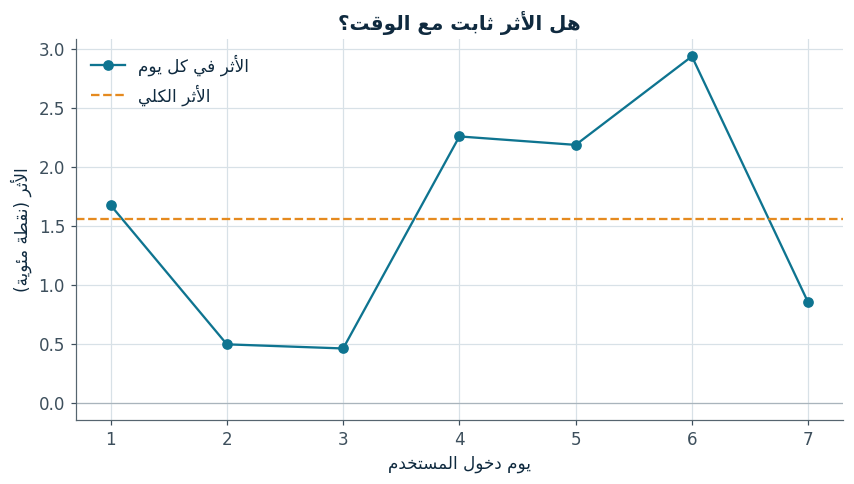

In [26]:
daily = data.groupby(["day", "variant"])["ordered"].mean().unstack()
daily_lift = (daily["B"] - daily["A"]) * 100
plt.plot(daily_lift.index, daily_lift.values, marker="o", color=TEAL, label=ar("الأثر في كل يوم"))
plt.axhline(primary["الفرق"] * 100, color=ORANGE, linestyle="--", label=ar("الأثر الكلي"))
plt.axhline(0, color=GRAY, linewidth=0.8)
plt.xlabel(ar("يوم دخول المستخدم"))
plt.ylabel(ar("الأثر (نقطة مئوية)"))
plt.title(ar("هل الأثر ثابت مع الوقت؟"))
plt.legend()
plt.show()

<div dir="rtl">

## 8. (اختياري) إذا لم تستطع إجراء تجربة: الفروق في الفروق

إذا كان مشروعك سياسة طُبقت في مناطق دون غيرها، فعدّل الإعدادات في الخلية التالية، وطبق خطوات اليوم الثالث نفسها.

</div>

In [27]:
def simulate_policy_panel(n_units=20, n_treated=6, n_periods=24, policy_period=13, effect=8.0, seed=32):
    r = np.random.default_rng(seed)
    level = r.normal(100, 15, n_units)
    shock = r.normal(0, 2, n_periods)
    rows = []
    for i in range(n_units):
        for t in range(1, n_periods + 1):
            treated, post = int(i < n_treated), int(t >= policy_period)
            y = level[i] + 0.8 * t + shock[t - 1] + effect * treated * post + r.normal(0, 3)
            rows.append({"unit": i, "period": t, "treated": treated, "post": post, "y": y})
    df = pd.DataFrame(rows)
    df["treated_post"] = df["treated"] * df["post"]
    return df


policy = simulate_policy_panel()
twfe = smf.ols("y ~ treated_post + C(unit) + C(period)", data=policy).fit(
    cov_type="cluster", cov_kwds={"groups": policy["unit"]})
lo, hi = twfe.conf_int().loc["treated_post"]
say(f"أثر السياسة: {twfe.params['treated_post']:.2f}، وفترة الثقة 95% من {lo:.2f} إلى {hi:.2f}")

<div dir="rtl">

## 9. التقرير والتوصية

الخلية التالية تنشئ تقرير الصفحة الواحدة من نتائج القسم 7. عدّل عدد المستخدمين السنوي حسب مشروعك.

</div>

In [28]:
annual_users = 2_000_000                 # عدّل: عدد المستخدمين في السنة الذين يتأثرون بالقرار
guardrails_ok = all(s == "سليم" for s in guard_status.values())
decision = decide(primary["أدنى 95%"], primary["أعلى 95%"], CONFIG["mde_abs"], guardrails_ok)
profit = guard_table.loc["الربح لكل مستخدم"]
guard_rows = "\n".join(f"| {k} | {v} |" for k, v in guard_status.items())

report = f"""
<div dir="rtl">

### تقرير التجربة: {CONFIG['project']}

**القرار:** {decision}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من {A['ordered'].mean():.2%} إلى {B['ordered'].mean():.2%} |
| الأثر | {primary['الفرق'] * 100:.2f} نقطة (فترة الثقة 95%: من {primary['أدنى 95%'] * 100:.2f} إلى {primary['أعلى 95%'] * 100:.2f}) |
| الأثر مع CUPED | {primary_cuped['الفرق'] * 100:.2f} نقطة (من {primary_cuped['أدنى 95%'] * 100:.2f} إلى {primary_cuped['أعلى 95%'] * 100:.2f}) |
| التغير التقديري في الربح السنوي | {profit['الفرق'] * annual_users / 1e6:.2f} مليون ريال (من {profit['أدنى 95%'] * annual_users / 1e6:.2f} إلى {profit['أعلى 95%'] * annual_users / 1e6:.2f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))


<div dir="rtl">

### تقرير التجربة: إشعار الخصم المؤقت والعداد التنازلي

**القرار:** نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من 4.91% إلى 6.46% |
| الأثر | 1.55 نقطة (فترة الثقة 95%: من 0.47 إلى 2.64) |
| الأثر مع CUPED | 1.47 نقطة (من 0.40 إلى 2.55) |
| التغير التقديري في الربح السنوي | 0.75 مليون ريال (من 0.05 إلى 1.46) |

| مقياس الحماية | الحالة |
|---|---|
| الربح لكل مستخدم | سليم |
| نسبة إلغاء الطلبات | سليم |
| التواصل مع الدعم | سليم |

</div>


<div dir="rtl">

**توصيتك النهائية والقيود** (من 3 إلى 5 أسطر):
نوصي باعتماد ميزة "إشعار الخصم المؤقت والعداد التنازلي" بشكل دائم، نظراً لثبوت تأثيرها الإيجابي في رفع معدلات الشراء وزيادة الأرباح السنوية للمتجر دون الإضرار بمقاييس الحماية.

</div>

<div dir="rtl">

## 10. التسليم على GitHub

يُسلَّم المشروع آخر اليوم الرابع مستودعًا على GitHub، ويُقيَّم منه. تعمل طوال الأيام الأربعة في نسختك على Drive، ثم تحفظ الدفتر في المستودع يوم الأربعاء.

**قبل يوم الأربعاء**

1. أنشئ حسابًا على [github.com](https://github.com) إن لم يكن لديك.
2. أنشئ مستودعًا جديدًا: من زر **New repository** اكتب اسمًا واضحًا مثل `free-delivery-ab-test`، واختر **Public**، وفعّل **Add a README file**، ثم **Create repository**.
3. في العمل الجماعي ينشئ عضو واحد المستودع، ويضيف زملاءه من **Settings** ثم **Collaborators**.

**آخر يوم الأربعاء، للتسليم**

1. في Colab اختر **File** ثم **Save a copy in GitHub**. في المرة الأولى وافق على ربط حسابك.
2. اختر مستودعك، واكتب في **Commit message** وصفًا قصيرًا، مثل: `النسخة النهائية من المشروع`، ثم اضغط **OK**.
3. افتح ملف `README.md` في المستودع، واضغط رمز القلم، والصق القالب الذي تحت هذه الخطوات، وأكمله.
4. ضع رابط المستودع، بالشكل `https://github.com/اسم-الحساب/اسم-المستودع`، في ملف التقييم.

**قالب README**

```markdown
# اسم المشروع
A\B-project
## الوصف
## السؤال والفرضية
- القرار:
- الفرضية:هل يؤدي إرسال إشعار فوري (Push Notification) يتضمن رسالة تحفيزية شخصية مع عداد تنازلي للخصم إلى زيادة معدل إتمام عمليات الشراء مقارنة بالإشعار العادي


## التصميم
- وحدة العشوأة:المستخدم الفريد
- المقياس الرئيسي ومقاييس الحماية: معدل اتمام عمليه الشراء
- حجم العينة والمدة:المستخدمون الجدد يومياً:** 1,000 مستخدم.
* **معدل التحويل الأساسي (Baseline Conversion):** 5% (0.05).
* **الفرق الأدنى الملحوظ (MDE Abs):** 2% (0.02).
* **توزيع العينة:** 50% للمجموعة الضابطة (A) و50% للمجموعة التجريبية (B).


## النتائج والتوصية
- الأثر الرئيسي وفترة الثقة:أظهر التحليل الإحصائي (باستخدام طريقة CUPED والتصحيحات) وجود فروق ذات دلالة إحصائية لصالح المجموعة التجريبية.
* ارتفاع ملحوظ في معدل التحويل وزيادة الإيرادات السنوية المتوقعة للمتجر دون تجاوز مقاييس الحماية.
- التوصية:نوصي باعتماد ميزة "إشعار الخصم المؤقت والعداد التنازلي" بشكل دائم في الحملات التسويقية؛ نظراً لثبوت تأثيرها الإيجابي في رفع معدلات الشراء وزيادة الأرباح دون الإضرار بمقاييس الحماية.


## طريقة التشغيل
1. افتح الدفتر في Google Colab: من GitHub افتح الملف ثم Open in Colab، أو من Colab اختر File ثم Open notebook ثم GitHub.
2. شغّل الخلايا بالترتيب. البيانات من محاكاة ببذرة ثابتة، فتتكرر النتائج نفسها.

## المتطلبات
Python 3 ومكتبات numpy وpandas وscipy وstatsmodels وmatplotlib، وكلها موجودة في Colab.

## التوثيق الفني
- القسم 3: حجم العينة والمدة.
- القسم 6: فحوص الثقة ونسبة التوزيع.
- القسم 7: التحليل مع CUPED وتصحيح الاختبارات المتعددة.
- القسم 9: التقرير والتوصية.

## هيكل المستودع
- project_template.ipynb: دفتر المشروع
- README.md: هذا الملف

## عن البرنامج
نُفّذ هذا المشروع ضمن برنامج «التجارب واختبارات A/B والاستدلال السببي» في أكاديمية سدايا، نوفمبر 2026.
حساب أكاديمية سدايا على GitHub: https://github.com/SDAIAAcademy
```

</div>

<div dir="rtl">

## قائمة التسليم

- المستودع عام على GitHub، وفيه الدفتر وملف README مكتملًا.
- رابط المستودع في ملف التقييم.
- الأقسام من 0 إلى 4 مكتوبة، وخطة التحليل مكتوبة قبل إنشاء البيانات.
- فحص نسبة التوزيع سليم، أو سبب الخلل موضح.
- الأثر الرئيسي معه فترة ثقة، والمقاييس الثانوية مصححة.
- حالة كل مقياس من مقاييس الحماية واضحة.
- تقرير الصفحة الواحدة جاهز، والتوصية موجودة في أول شريحة وآخر شريحة من العرض.

</div>